  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
(5172, 3002)
0

 KNN Results
Accuracy: 0.8714975845410629
Prec

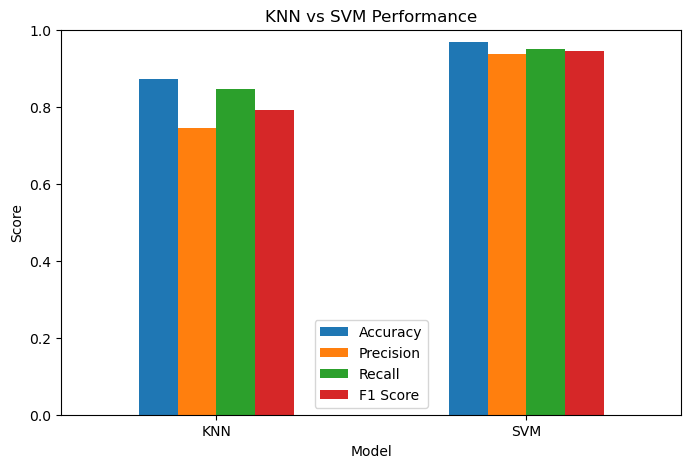

SVM performs better in terms of accuracy.


In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report

# 2. Load dataset
df = pd.read_csv(r"C:\Users\Ritesh Bhosale\Downloads\BE prac\ML\Prac 2\emails.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum().sum())

# 3. Preprocess dataset
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

# Remove email ID column
df.drop(columns=['Email No.'], errors='ignore', inplace=True)

# Separate features and target
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# 4. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. K-Nearest Neighbors (KNN)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

# 6. Support Vector Machine (SVM)
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

# 7. Evaluate models
def evaluate_model(name, y_test, y_pred):
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

evaluate_model("KNN Results", y_test, y_pred_knn)
evaluate_model("SVM Results", y_test, y_pred_svm)

# 8. Compare model performance
results = pd.DataFrame({
    'Model': ['KNN', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Precision': [
        precision_score(y_test, y_pred_knn, zero_division=0),
        precision_score(y_test, y_pred_svm, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_knn, zero_division=0),
        recall_score(y_test, y_pred_svm, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_knn, zero_division=0),
        f1_score(y_test, y_pred_svm, zero_division=0)
    ]
})

print("\nModel Comparison:")
print(results)

results.set_index('Model').plot(kind='bar', figsize=(8, 5))
plt.title("KNN vs SVM Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

# 9. Conclusion
if accuracy_score(y_test, y_pred_knn) > accuracy_score(y_test, y_pred_svm):
    print("KNN performs better in terms of accuracy.")
elif accuracy_score(y_test, y_pred_svm) > accuracy_score(y_test, y_pred_knn):
    print("SVM performs better in terms of accuracy.")
else:
    print("Both models have equal accuracy.")